In [1]:
import pandas as pd
from pathlib import Path

csv_path = Path("..") /"1. Données"/"02_intermediate"/"welddb_processed.csv"
weld_data = pd.read_csv(csv_path, sep=";") 

In [2]:
print(weld_data.shape)
print(weld_data.info())

(1652, 44)
<class 'pandas.DataFrame'>
RangeIndex: 1652 entries, 0 to 1651
Data columns (total 44 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Carbon concentration                  1652 non-null   float64
 1   Silicon concentration                 1652 non-null   float64
 2   Manganese concentration               1652 non-null   float64
 3   Sulphur concentration                 1648 non-null   str    
 4   Phosphorus concentration              1642 non-null   float64
 5   Nickel concentration                  697 non-null    float64
 6   Chromium concentration                784 non-null    float64
 7   Molybdenum concentration              793 non-null    str    
 8   Vanadium concentration                928 non-null    str    
 9   Copper concentration                  578 non-null    str    
 10  Cobalt concentration                  129 non-null    str    
 11  Tungsten concentr

### Séparation des variables explicatives et des sorties

La coupure est effectuée à la 31e colonne (`Yield strength`, d'indice 30 en Python), car les 30 premières colonnes décrivent la composition chimique et les conditions de soudage : elles constituent les variables explicatives `X`. De `Yield strength` à `Ferrite with carbide aggreagate`, les colonnes décrivent les propriétés mécaniques et la microstructure obtenues après soudage : elles constituent les sorties `y` à prédire.

La dernière colonne, `Weld ID`, n'est conservée ni dans `X` ni dans `y` car il s'agit d'un identifiant et non d'une grandeur physique. L'utiliser comme variable explicative pourrait conduire le modèle à mémoriser les soudures du jeu d'entraînement sans apprendre de relation généralisable. Elle peut néanmoins être conservée séparément pour assurer la traçabilité des observations.

In [3]:
X = weld_data.iloc[:, :30]
y = weld_data.iloc[:, 30:43]

### Suppression des variables trop incomplètes

`MissingRateDropper` est un transformer compatible avec les pipelines scikit-learn. Lors de `fit`, il calcule la proportion de valeurs manquantes de chaque variable et mémorise celles dont cette proportion ne dépasse pas le seuil fixé. Lors de `transform`, il conserve uniquement ces variables, ce qui garantit que la sélection apprise sur le jeu d'entraînement est appliquée à l'identique aux autres jeux de données.

In [4]:
from sklearn.base import BaseEstimator, TransformerMixin

class MissingRateDropper(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.60):
        self.threshold = threshold

    def fit(self, X, y=None):
        self.missing_rates_ = X.isna().mean()
        self.columns_to_keep_ = self.missing_rates_[
            self.missing_rates_ <= self.threshold
        ].index.tolist()

        self.columns_to_drop_ = self.missing_rates_[
            self.missing_rates_ > self.threshold
        ].index.tolist()

        return self

    def transform(self, X):
        return X.loc[:, self.columns_to_keep_].copy()

    def get_feature_names_out(self, input_features=None):
        return self.columns_to_keep_

In [21]:
dropper = MissingRateDropper()

X_reduced = dropper.fit_transform(X)

print("Colonnes supprimées :")
print(dropper.columns_to_drop_)
print(X_reduced.info)

Colonnes supprimées :
['Copper concentration', 'Cobalt concentration', 'Tungsten concentration', 'Boron concentration', 'Tin concentration', 'Arsenic concentration', 'Antimony concentration']
<bound method DataFrame.info of       Carbon concentration  Silicon concentration  Manganese concentration  \
0                    0.037                   0.30                     0.65   
1                    0.037                   0.30                     0.65   
2                    0.037                   0.30                     0.65   
3                    0.037                   0.31                     1.03   
4                    0.037                   0.31                     1.03   
...                    ...                    ...                      ...   
1647                 0.100                   0.35                     0.90   
1648                 0.088                   0.36                     0.88   
1649                 0.090                   0.34                     0.89

Nous avons choisi un seuil de **60 % de valeurs manquantes** : toute variable dépassant ce seuil est supprimée. Après cette sélection, `X_reduced` contient **23 variables prédictives**.

Nous examinons maintenant le type et les valeurs de ces variables afin d'appliquer le traitement approprié : les variables catégorielles seront encodées, tandis que les variables numériques stockées comme du texte seront converties en nombres. Une attention particulière sera portée aux valeurs exprimées sous forme de seuil, comme `<0.002`, qui nécessitent une règle de conversion explicite.

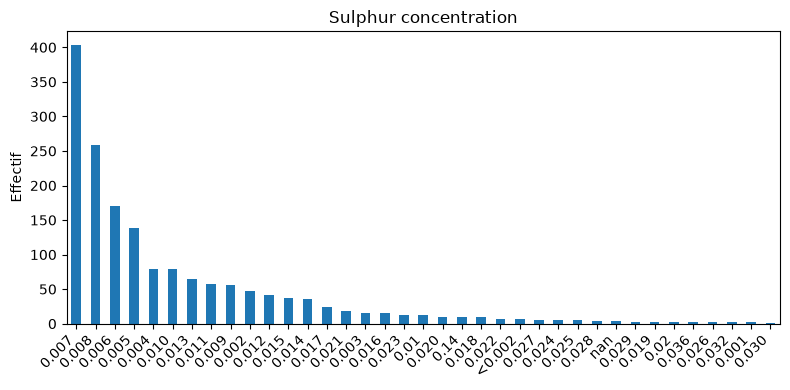

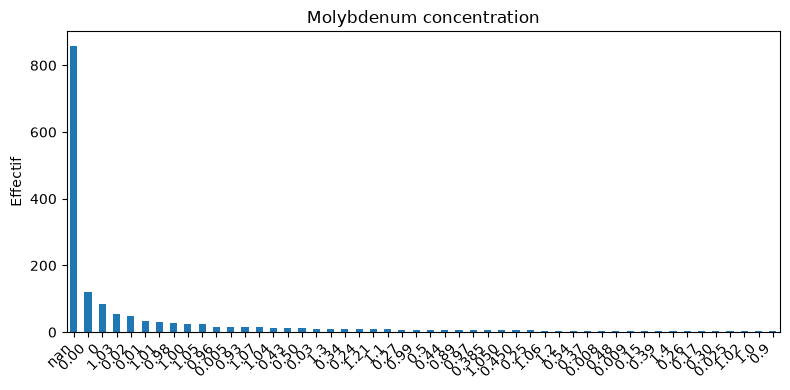

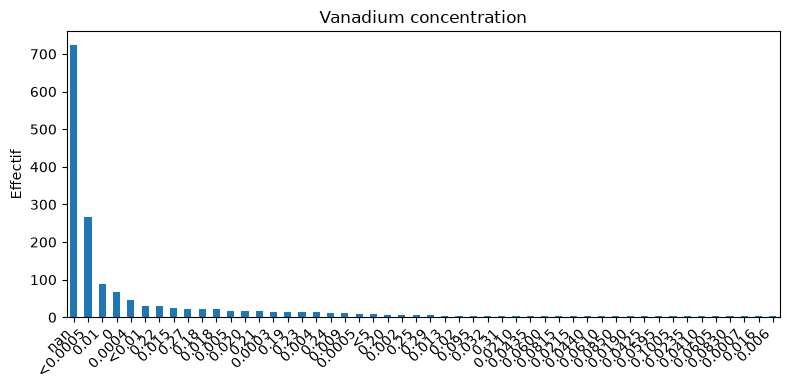

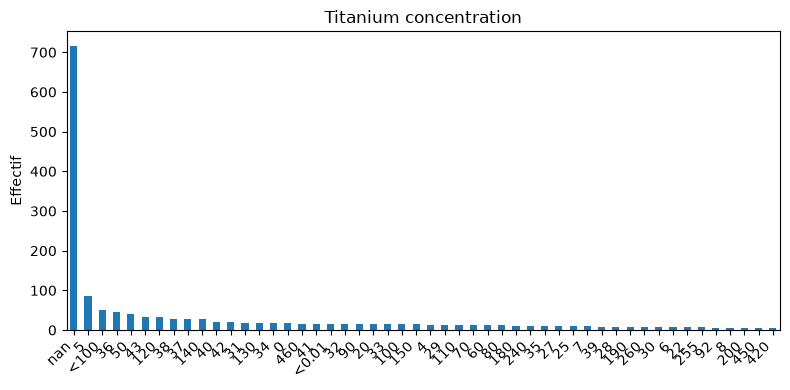

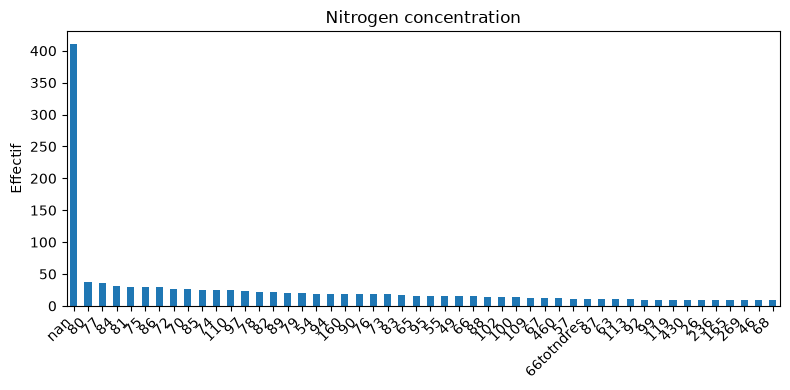

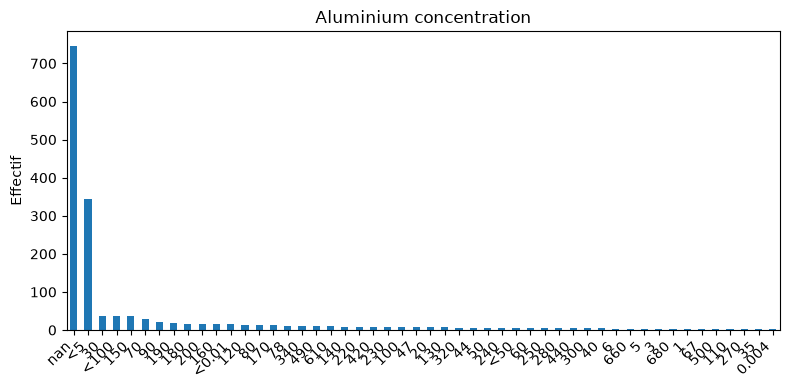

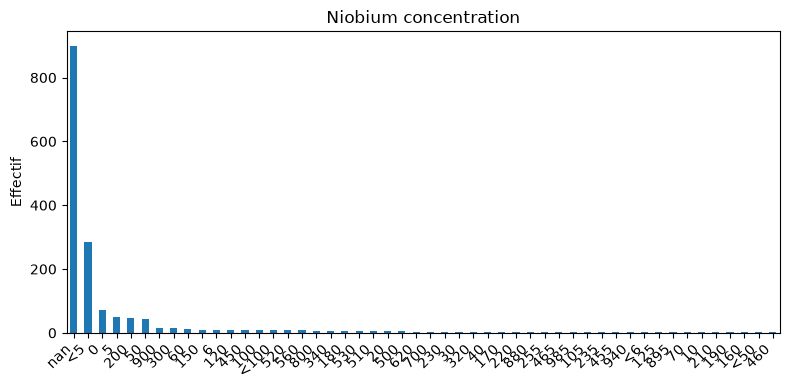

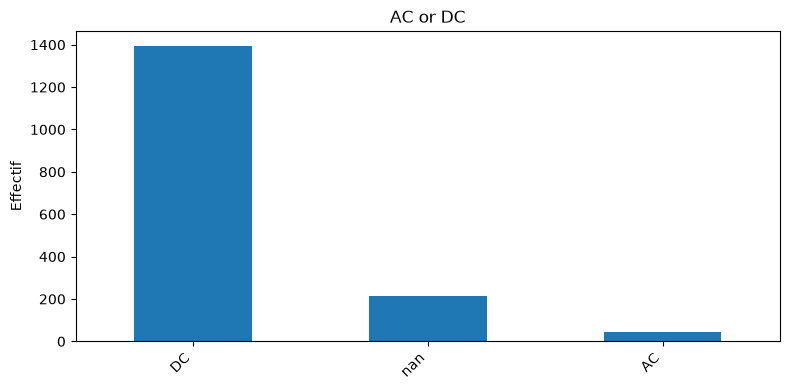

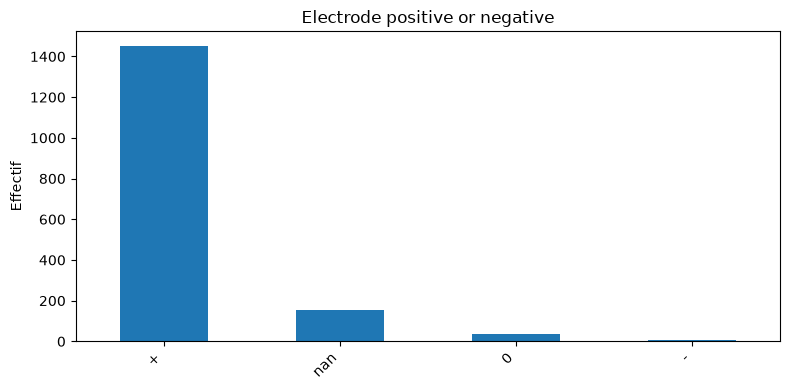

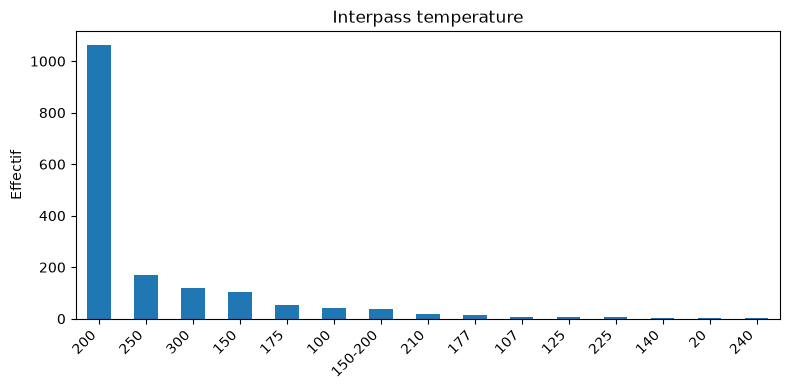

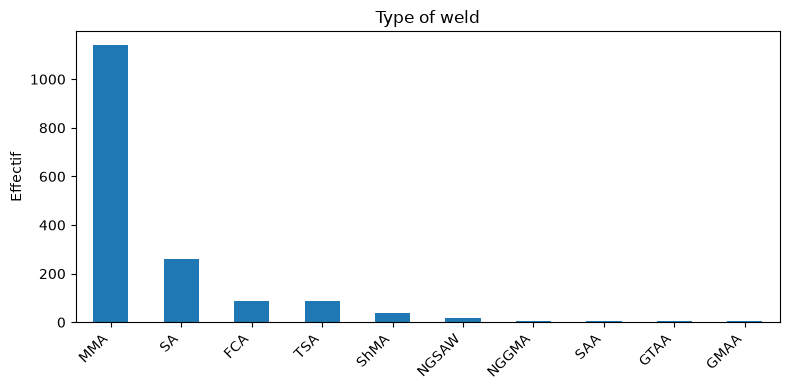

In [28]:
import matplotlib.pyplot as plt
columns = X_reduced.select_dtypes(exclude='number').columns

for col in columns:
    X_reduced[col].value_counts(dropna=False).head(50).plot(
        kind="bar",
        figsize=(8, 4)
    )

    plt.title(col)
    plt.xlabel("")
    plt.ylabel("Effectif")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    


### Principaux problèmes de formatage des données observés

L'inspection des variables stockées comme du texte met en évidence plusieurs situations différentes. Toutes ces colonnes ne sont donc pas nécessairement catégorielles : certaines correspondent à des mesures numériques dont l'écriture empêche la conversion directe en nombre.

1. **Valeurs exprimées par un seuil (`<`)** : des valeurs comme `<0.002` indiquent que la mesure est inférieure à une limite de détection. La valeur exacte n'est pas connue ; elle est seulement comprise entre zéro et le seuil indiqué. Une règle de remplacement explicite est donc nécessaire avant la conversion en nombre.

2. **Valeurs exprimées par une fourchette (`-`)** : certaines cellules décrivent un intervalle plutôt qu'une mesure unique. Il faudra distinguer ces tirets des signes négatifs, puis choisir une représentation adaptée, par exemple le milieu de l'intervalle ou deux variables contenant ses bornes inférieure et supérieure.

3. **Valeurs non interprétables dans `Nitrogen concentration`** : cette variable contient notamment les chaînes `66totndres` et `54totndres`. Leur signification et leur unité ne sont pas suffisamment claires pour les convertir automatiquement. Extraire uniquement la partie numérique risquerait d'introduire une valeur erronée ; ces observations devront être confrontées à la source ou au dictionnaire des données, puis corrigées ou considérées comme manquantes si elles restent indéterminées.

4. **Variables réellement catégorielles** : `AC or DC`, `Electrode positive or negative` et `Type of weld` décrivent des modalités et non des quantités continues. Elles devront être nettoyées et harmonisées si nécessaire, puis encodées avant l'entraînement du modèle.

La suite du prétraitement doit donc séparer les **colonnes numériques mal formatées**, qui nécessitent une règle de conversion documentée, des **colonnes catégorielles**, qui nécessitent un encodage.

### Analyse du pourcentage des valeurs exprimées par un seuil

In [27]:
text_columns = X_reduced.select_dtypes(include=["object", "string"])

less_than_counts = text_columns.apply(
    lambda column: (
        column.astype("string")
        .str.strip()
        .str.startswith("<", na = False)
        .mean()
        *100
    )
)

less_than_counts=less_than_counts[less_than_counts>0].sort_values(ascending=False)
less_than_counts.round(2)

Aluminium concentration     24.39
Vanadium concentration      18.64
Niobium concentration       18.10
Titanium concentration       4.24
Sulphur concentration        0.42
Molybdenum concentration     0.12
dtype: float64

### Traitement des valeurs exprimées par un seuil

Les histogrammes montrent que certaines variables a priori numériques, notamment `Sulphur concentration`, sont considérées comme catégorielles parce qu'elles contiennent des valeurs telles que `<0.002`. Cette écriture ne correspond pas à une catégorie : elle indique que la concentration mesurée est **inférieure à la limite de détection**. La valeur exacte est donc inconnue et comprise entre zéro et le seuil indiqué.

Nous faisons ici l'hypothèse que ces observations restent du même ordre de grandeur que leur seuil. Une valeur comme `<0.002` est donc remplacée par `0.002`. Ce choix correspond à la stratégie `limit` du transformer ci-dessous. Comme cette substitution assimile une borne supérieure à une mesure exacte, une variable indicatrice est également créée afin que le modèle puisse distinguer une valeur réellement égale au seuil d'une valeur seulement connue comme inférieure à celui-ci.

In [ ]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin


class DetectionLimitTransformer(BaseEstimator, TransformerMixin):
    """Convertit les valeurs censurées comme '<0.002' en nombres."""

    def __init__(self, columns=None, strategy="limit", add_indicator=True):
        self.columns = columns
        self.strategy = strategy
        self.add_indicator = add_indicator

    def fit(self, X, y=None):
        valid_strategies = {"limit", "half", "zero", "nan"}
        if self.strategy not in valid_strategies:
            raise ValueError(
                f"strategy doit appartenir à {valid_strategies}."
            )

        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.columns_ = (
            list(X.select_dtypes(include="object").columns)
            if self.columns is None
            else list(self.columns)
        )

        missing_columns = set(self.columns_) - set(X.columns)
        if missing_columns:
            raise ValueError(f"Colonnes absentes : {sorted(missing_columns)}")

        return self

    def transform(self, X):
        X_transformed = X.copy()

        for column in self.columns_:
            values = X_transformed[column].astype("string").str.strip()
            is_below_limit = values.str.match(
                r"^<\s*(?:\d+(?:[.,]\d+)?|[.,]\d+)$",
                na=False,
            )

            numeric_values = pd.to_numeric(
                values.str.replace("<", "", regex=False)
                .str.replace(",", ".", regex=False),
                errors="coerce",
            )

            if self.strategy == "half":
                numeric_values = numeric_values.where(
                    ~is_below_limit, numeric_values / 2
                )
            elif self.strategy == "zero":
                numeric_values = numeric_values.where(~is_below_limit, 0)
            elif self.strategy == "nan":
                numeric_values = numeric_values.where(~is_below_limit, np.nan)

            X_transformed[column] = numeric_values.astype(float)

            if self.add_indicator:
                indicator_name = f"{column}_below_detection_limit"
                X_transformed[indicator_name] = is_below_limit.astype("int8")

        return X_transformed

    def get_feature_names_out(self, input_features=None):
        feature_names = list(
            self.feature_names_in_ if input_features is None else input_features
        )
        if self.add_indicator:
            feature_names.extend(
                f"{column}_below_detection_limit"
                for column in self.columns_
            )
        return np.asarray(feature_names, dtype=object)


detection_limit_transformer = DetectionLimitTransformer(
    columns=["Sulphur concentration"],
    strategy="limit",
    add_indicator=True,
)

X_reduced = detection_limit_transformer.fit_transform(X_reduced)

X_reduced[[
    "Sulphur concentration",
    "Sulphur concentration_below_detection_limit",
]].head()

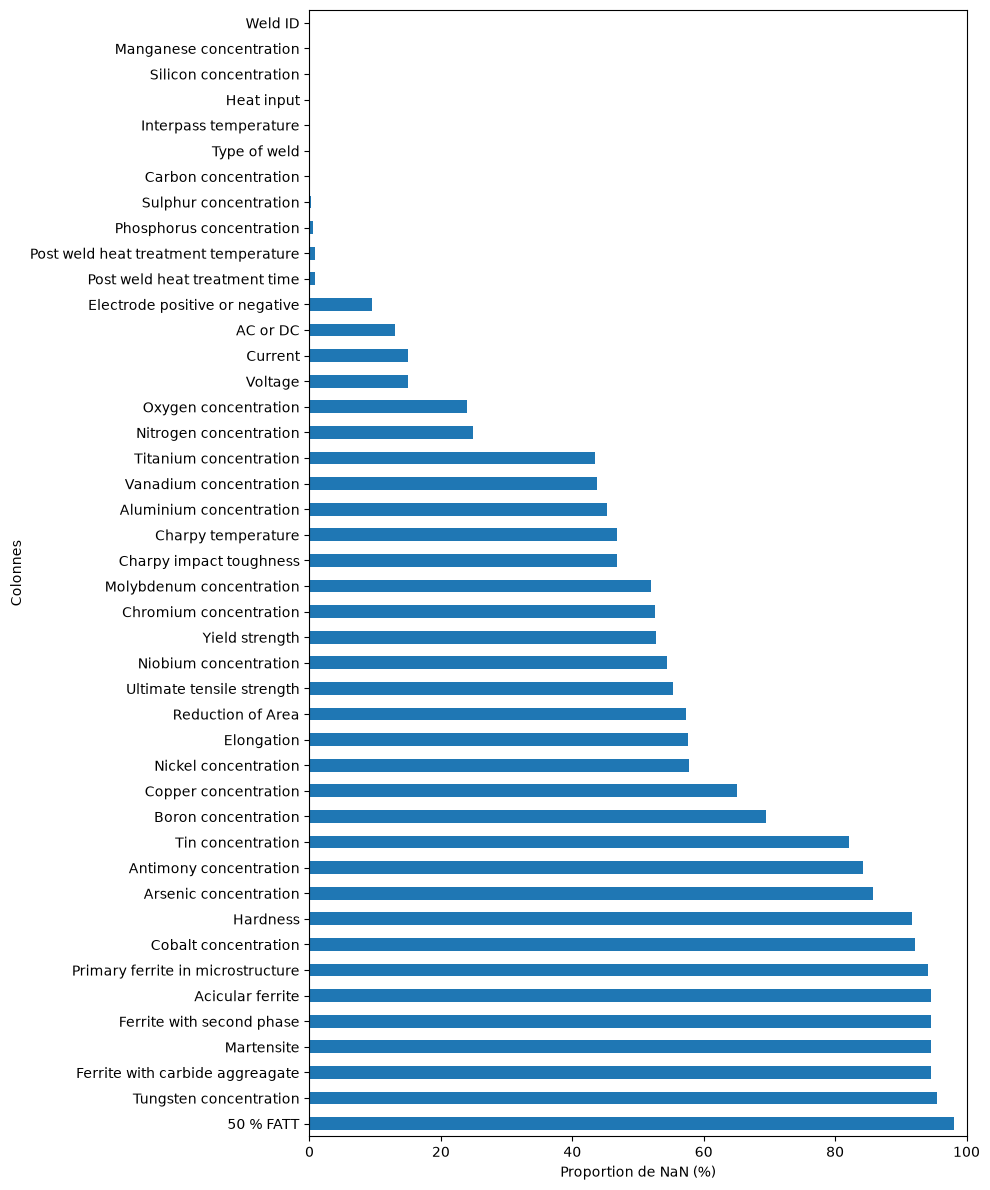

In [ ]:
proportion_nan = (
    weld_data.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("Proportion de Nan (%)")
)

plt.figure(figsize=(10,12))
proportion_nan.plot(kind="barh")

plt.xlabel("Proportion de NaN (%)")
plt.ylabel("Colonnes")
plt.xlim(0,100)
plt.tight_layout()
plt.show()
